NumPy gave us fast arrays of numbers. Real data is not just numbers: it has **labels**. A price belongs to a ticker and a date; a return series has gaps on holidays; two data sources disagree on which days exist. pandas adds those labels to NumPy arrays and, crucially, **lines data up by label automatically**. That single feature removes a whole family of bugs, and it is why pandas is the standard tool for financial data.

In this chapter we use real data: daily prices of ten ETFs and stocks from 2010 to October 2025 (from Yahoo Finance) and three US series from FRED (the 3-month Treasury bill rate, the 10-year Treasury yield and the VIX volatility index). Both files are in the chapter's `datasets/` folder.

:::eli5
A NumPy array is a grid of numbers. A pandas table is the same grid with a name on every row and every column, like a spreadsheet. When you add two pandas columns, pandas matches rows by their names (for us, the dates) before adding, the way you would match two lists of birthdays by person, not by line number.
:::

## Setup

In [1]:
import sys
assert sys.version_info >= (3, 9)
import numpy as np
import pandas as pd
print("pandas", pd.__version__, "| NumPy", np.__version__)

import matplotlib as mpl
import matplotlib.pyplot as plt
mpl.rc("axes", labelsize=12, titlesize=13)
mpl.rc("figure", dpi=110)
pd.set_option("display.width", 110)
pd.set_option("display.max_columns", 12)
pd.set_option("display.precision", 4)

from pathlib import Path
IMAGES = Path("images"); IMAGES.mkdir(exist_ok=True)
DATA = Path("datasets")

def save_fig(name):
    plt.tight_layout()
    plt.savefig(IMAGES / f"{name}.png", dpi=150, bbox_inches="tight")

R = {}

pandas 3.0.5 | NumPy 2.5.3


:::note
This chapter is written for pandas 2.2 or newer, including pandas 3. pandas 3 turned on **copy-on-write** (explained below) and a dedicated string type; the code here works the same on both.
:::

## Series: an array with an index

A `Series` is a 1-D NumPy array plus an **index**: a label for each value.

In [2]:
s = pd.Series([101.2, 102.5, 101.9], index=["2025-10-01", "2025-10-02", "2025-10-03"], name="SPY")
print(s)
print("values:", s.to_numpy(), "| index:", list(s.index))
print(s["2025-10-02"], s.iloc[0])      # by label, by position

2025-10-01    101.2
2025-10-02    102.5
2025-10-03    101.9
Name: SPY, dtype: float64
values: [101.2 102.5 101.9] | index: ['2025-10-01', '2025-10-02', '2025-10-03']
102.5 101.2


Arithmetic between two Series **aligns on the index first**. Labels present in only one of them give `NaN`, which tells you something did not match instead of silently pairing the wrong rows.

In [3]:
a = pd.Series([1.0, 2.0, 3.0], index=["Mon", "Tue", "Wed"])
b = pd.Series([10.0, 20.0, 30.0], index=["Tue", "Wed", "Thu"])
print(a + b)
print("NumPy would pair by position:", a.to_numpy() + b.to_numpy())

Mon     NaN
Thu     NaN
Tue    12.0
Wed    23.0
dtype: float64
NumPy would pair by position: [11. 22. 33.]


:::idea
Alignment is the reason pandas exists. Two price series from different exchanges have different holidays; a stock that listed in 2012 has no data for 2010. pandas matches them by date and marks the gaps. With raw arrays you would have to do this by hand, and an off-by-one-day error in finance means using tomorrow's price today.
:::

## DataFrame: a table of aligned Series

A `DataFrame` is a dictionary of Series sharing one index. Each column has its own dtype.

In [4]:
df = pd.DataFrame({
    "ticker": ["AAPL", "MSFT", "KO"],
    "price": [270.4, 517.8, 69.1],
    "shares": [10, 4, 25],
})
df["value"] = df["price"] * df["shares"]      # a new column, vectorised
print(df)
print(df.dtypes)
print("total value:", df["value"].sum())

  ticker  price  shares   value
0   AAPL  270.4      10  2704.0
1   MSFT  517.8       4  2071.2
2     KO   69.1      25  1727.5
ticker        str
price     float64
shares      int64
value     float64
dtype: object
total value: 6502.7


## Loading real data

`pd.read_csv` is the workhorse. Tell it which columns are dates with `parse_dates`; otherwise dates are just text.

In [5]:
prices = pd.read_csv(DATA / "prices_long.csv", parse_dates=["date"])
print(prices.shape)
prices.head()

(39830, 8)


,date,ticker,open,high,low,close,adj_close,volume
0,2010-01-04,AAPL,7.6225,7.6607,7.5850,7.6432,6.4010,493729600
1,2010-01-05,AAPL,7.6643,7.6996,7.6161,7.6564,6.4120,601904800
2,2010-01-06,AAPL,7.6564,7.6868,7.5268,7.5346,6.3100,552160000
3,2010-01-07,AAPL,7.5625,7.5714,7.4661,7.5207,6.2984,477131200
4,2010-01-08,AAPL,7.5107,7.5714,7.4664,7.5707,6.3402,447610800


In [6]:
prices.info()

<class 'pandas.DataFrame'>
RangeIndex: 39830 entries, 0 to 39829
Data columns (total 8 columns):
 #   Column     Non-Null Count  Dtype         
---  ------     --------------  -----         
 0   date       39830 non-null  datetime64[us]
 1   ticker     39830 non-null  str           
 2   open       39830 non-null  float64       
 3   high       39830 non-null  float64       
 4   low        39830 non-null  float64       
 5   close      39830 non-null  float64       
 6   adj_close  39830 non-null  float64       
 7   volume     39830 non-null  int64         
dtypes: datetime64[us](1), float64(5), int64(1), str(1)
memory usage: 2.5 MB


The file is in **long format**: one row per (date, ticker) pair. That is how databases store prices. `close` is the trading price (adjusted for stock splits by Yahoo), `adj_close` is additionally adjusted for dividends, and `volume` is the number of shares traded.

In [7]:
print(prices["ticker"].unique())
print(prices["ticker"].value_counts().head(3))
prices.describe().T

<ArrowStringArray>
['AAPL', 'EEM', 'GLD', 'JPM', 'KO', 'MSFT', 'QQQ', 'SPY', 'TLT', 'XOM']
Length: 10, dtype: str
ticker
AAPL    3983
EEM     3983
GLD     3983
Name: count, dtype: int64


,count,mean,min,25%,50%,75%,max,std
date,39830,2017-11-30 18:25:34.722571,2010-01-04 00:00:00,2013-12-16 00:00:00,2017-11-29 00:00:00,2021-11-12 00:00:00,2025-10-31 00:00:00,NaN
open,39830.0,127.4089,6.8704,46.07,97.895,155.8,688.72,112.6369
high,39830.0,128.2822,7.0,46.38,98.735,156.9175,689.7,113.3532
low,39830.0,126.4993,6.7946,45.79,97.22,154.685,684.83,111.8482
close,39830.0,127.436,6.8589,46.09,98.0,155.985,687.39,112.657
adj_close,39830.0,114.7475,5.7441,38.098,80.4745,143.553,680.0531,112.118
volume,39830.0,54081801.17,987200.0,12419650.0,24732150.0,56734550.0,1880998000.0,96161308.9196


## Selecting data: `[]`, `.loc`, `.iloc`

There are three ways to select, and mixing them up is the most common pandas confusion:

| Syntax | Selects by | Example |
|---|---|---|
| `df["col"]`, `df[["a", "b"]]` | column name(s) | `prices["close"]` |
| `df.loc[rows, cols]` | **labels** (index values, column names, boolean masks) | `df.loc["2020-03", "SPY"]` |
| `df.iloc[rows, cols]` | **positions** (0, 1, 2, …) | `df.iloc[-5:, 0]` |

In [8]:
spy = prices[prices["ticker"] == "SPY"]               # boolean mask on rows
print(spy[["date", "close", "volume"]].tail(3))
big_days = prices.loc[prices["volume"] > 5e8, ["date", "ticker", "volume"]]
print(len(big_days), "rows with more than 500 million shares traded;", big_days["ticker"].unique())
print(prices.query("ticker == 'KO' and close > 70").shape)   # the same idea as a string

            date   close    volume
31861 2025-10-29  687.39  85657100
31862 2025-10-30  679.83  76335800
31863 2025-10-31  682.06  87164100
433 rows with more than 500 million shares traded; <ArrowStringArray>
['AAPL', 'SPY']
Length: 2, dtype: str


(122, 8)


### Setting values the right way (copy-on-write)

Writing `df[df.a > 0]["b"] = 1` is **chained assignment**: the first `[]` makes a new object and the second writes into it, so the original never changes. Modern pandas (copy-on-write, the default in pandas 3) guarantees that any object you get from indexing behaves as a copy. To modify a DataFrame, always use one `.loc` call.

In [9]:
d = pd.DataFrame({"r": [0.01, -0.02, 0.03], "signal": 0})
d.loc[d["r"] > 0, "signal"] = 1            # one .loc: rows and column together
print(d)

      r  signal
0  0.01       1
1 -0.02       0
2  0.03       1


:::trap
If you write `sub = df[df.ticker == "SPY"]` and then modify `sub`, the original `df` is not changed (with copy-on-write). That is usually what you want. If you *meant* to change `df`, use `df.loc[mask, col] = …`.
:::

## From long to wide: one column per ticker

Most analysis wants a **wide** table: dates down the rows, one column per asset. `pivot` reshapes long into wide; `melt` goes back.

In [10]:
close = prices.pivot(index="date", columns="ticker", values="adj_close")
print(close.shape)
close.tail(3)

(3983, 10)


ticker,AAPL,EEM,GLD,JPM,KO,MSFT,QQQ,SPY,TLT,XOM
date,,,,,,,,,,
2025-10-29,268.7074,54.9342,363.00,299.7372,66.5800,537.1306,632.7968,680.0531,87.4026,113.1700
2025-10-30,270.4011,54.3654,370.13,303.5929,67.1937,521.4695,623.1223,672.5738,86.8941,111.4596
2025-10-31,269.3749,54.2379,368.12,305.2411,67.1158,513.5844,626.1281,674.7800,86.6350,111.1389


In [11]:
back = close.reset_index().melt(id_vars="date", var_name="ticker", value_name="adj_close")
print(back.head(3)); print(len(back), "rows (NaN cells included)")

        date ticker  adj_close
0 2010-01-04   AAPL      6.401
1 2010-01-05   AAPL      6.412
2 2010-01-06   AAPL      6.310
39830 rows (NaN cells included)


The **Reshape** tab of the playground below animates `pivot` and `melt` on a tiny table.

::playground animations/pandas_playground.html 640

## The DatetimeIndex: dates as the index

With dates as the index, you can select periods with strings, and pandas understands calendars.

In [12]:
print(type(close.index), close.index.min().date(), "→", close.index.max().date())
print(close.loc["2020-03-16", ["SPY", "TLT", "GLD"]])        # one day
covid = close.loc["2020-02-19":"2020-03-23", "SPY"]                # the COVID crash
print(f"first {covid.iloc[0]:.2f}, last {covid.iloc[-1]:.2f}, low {covid.min():.2f} on {covid.idxmin().date()}")
print("trading days in 2024:", close.loc["2024"].shape[0])

<class 'pandas.DatetimeIndex'> 2010-01-04 → 2025-10-31
ticker
SPY    218.0864
TLT    134.4127
GLD    141.6400
Name: 2020-03-16 00:00:00, dtype: float64
first 307.64, last 203.91, low 203.91 on 2020-03-23
trading days in 2024: 252


### Returns: `pct_change`, `shift` and log returns

In [13]:
rets = close.pct_change(fill_method=None)              # P_t / P_{t-1} - 1, per column
logr = np.log(close).diff()                            # ln P_t - ln P_{t-1}
print(rets[["SPY", "AAPL"]].tail(3))
same = (close / close.shift(1) - 1)                    # what pct_change does
print("identical:", np.allclose(same.dropna(), rets.dropna()))

ticker         SPY    AAPL
date                      
2025-10-29  0.0005  0.0026
2025-10-30 -0.0110  0.0063
2025-10-31  0.0033 -0.0038
identical: True


`shift(1)` moves every value one row **down**: on each date you see yesterday's value. That is exactly how you avoid look-ahead bias: a signal computed with data up to today can only be traded from tomorrow.

:::trap
`shift(-1)` moves values **up**: tomorrow's value appears today. It is the right tool to build a *target* (what you want to predict), and the most dangerous line in quant finance if it leaks into your *features*. Every backtest bug that looks too good to be true starts here. The **Shift** tab of the playground shows both directions.
:::

### Price return versus total return

`close` ignores dividends; `adj_close` reinvests them. For high-dividend assets the difference is huge.

In [14]:
def total_growth(px):
    px = px.dropna()
    return px.iloc[-1] / px.iloc[0]

wide_close = prices.pivot(index="date", columns="ticker", values="close")
cmp = pd.DataFrame({
    "price return": wide_close.apply(total_growth) - 1,
    "total return": close.apply(total_growth) - 1,
}).sort_values("total return")
cmp["gap"] = cmp["total return"] - cmp["price return"]
print(cmp.round(2))
R["tlt_price"] = f"{cmp.loc['TLT', 'price return']:+.0%}"
R["tlt_total"] = f"{cmp.loc['TLT', 'total return']:+.0%}"

        price return  total return   gap
ticker                                  
TLT             0.01          0.57  0.57
EEM             0.29          0.80  0.50
XOM             0.65          1.99  1.34
GLD             2.35          2.35  0.00
KO              1.42          2.92  1.51
SPY             5.02          7.00  1.98
JPM             6.26          9.90  3.64
QQQ            12.55         14.57  2.02
MSFT           15.73         21.35  5.61
AAPL           34.37         41.08  6.71


Long Treasury bonds (TLT) show +1% on price alone but +57% once their interest payments are counted. Any backtest that uses unadjusted closes for a dividend-paying asset is wrong.

## Missing data

`NaN` marks a missing value. In price tables it comes from holidays that differ between sources, assets that did not exist yet, and data errors.

In [15]:
merged = close.join(pd.read_csv(DATA / "fred_rates.csv", index_col="date", parse_dates=True))
print(merged.isna().sum().tail(4))
print(merged.loc["2024-11-07":"2024-11-13", ["SPY", "DGS10", "VIXCLS"]])

XOM        0
DGS3MO    29
DGS10     29
VIXCLS     0
dtype: int64
                 SPY  DGS10  VIXCLS
date                               
2024-11-07  582.1750   4.31   15.20
2024-11-08  584.6968   4.30   14.94
2024-11-11  585.2539    NaN   14.97
2024-11-12  583.4359   4.43   14.71
2024-11-13  583.7194   4.44   14.02


On 11 November 2024 (Veterans Day) the stock market was open but the bond market was closed, so the Treasury yield is missing while SPY has a price. The fixes:

In [16]:
m = merged[["SPY", "DGS10", "VIXCLS"]]
print("drop rows with any NaN:", m.dropna().shape)
print("forward fill:", m.ffill().isna().sum().to_dict())
print(m.loc["2024-11-11"].to_dict(), "→ ffill →", m.ffill().loc["2024-11-11"].to_dict())

drop rows with any NaN: (3954, 3)
forward fill: {'SPY': 0, 'DGS10': 0, 'VIXCLS': 0}


{'SPY': 585.2539, 'DGS10': nan, 'VIXCLS': 14.97} → ffill → {'SPY': 585.2539, 'DGS10': 4.3, 'VIXCLS': 14.97}


:::trap
`ffill()` (carry the last known value forward) is safe: on each day it uses only the past. `bfill()` (fill from the next value) and `interpolate()` use the **future**, so they leak information into a backtest. Use them only for plotting, never for signals.
:::

## Resampling: changing the frequency

`resample` groups the time index into bins (weeks, months, years) and aggregates each bin. To get monthly returns from daily prices, take the last price of each month, then compute returns.

In [17]:
monthly_px = close.resample("ME").last()        # "ME" = month end
monthly_ret = monthly_px.pct_change(fill_method=None)
print(monthly_ret[["SPY", "TLT", "GLD"]].tail(4))
yearly = close.resample("YE").last().pct_change(fill_method=None)
yearly.index = yearly.index.year
print(yearly.loc[2018:2025, ["SPY", "QQQ", "TLT", "GLD"]].round(3))

ticker         SPY     TLT     GLD
date                              
2025-07-31  0.0230 -0.0114 -0.0061
2025-08-31  0.0205  0.0001  0.0499
2025-09-30  0.0356  0.0359  0.1176
2025-10-31  0.0238  0.0138  0.0356


ticker    SPY    QQQ    TLT    GLD
date                              
2018   -0.046 -0.001 -0.016 -0.019
2019    0.312  0.390  0.141  0.179
2020    0.183  0.484  0.182  0.248
2021    0.287  0.274 -0.046 -0.041
2022   -0.182 -0.326 -0.312 -0.008
2023    0.262  0.549  0.028  0.127
2024    0.249  0.256 -0.081  0.267
2025    0.174  0.235  0.068  0.520


Prices aggregate with `last` (or `ohlc` for candles), volumes with `sum`, returns by compounding:

In [18]:
spy_daily = prices[prices.ticker == "SPY"].set_index("date")
weekly = spy_daily.resample("W-FRI").agg({"open": "first", "high": "max", "low": "min", "close": "last", "volume": "sum"})
print(weekly.tail(3))
r = rets["SPY"]
compounded = (1 + r).resample("ME").prod() - 1
print("compounding daily returns = monthly return:", np.allclose(compounded.iloc[1:], monthly_ret["SPY"].iloc[1:]))

              open    high     low   close     volume
date                                                 
2025-10-17  660.65  670.23  653.17  664.39  457106900
2025-10-24  667.32  678.47  663.30  677.25  337267400
2025-10-31  682.73  689.70  679.24  682.06  374234900
compounding daily returns = monthly return: True


## Rolling, expanding and exponential windows

Rolling windows are the bread and butter of signals and risk: moving averages, rolling volatility, rolling correlations and betas.

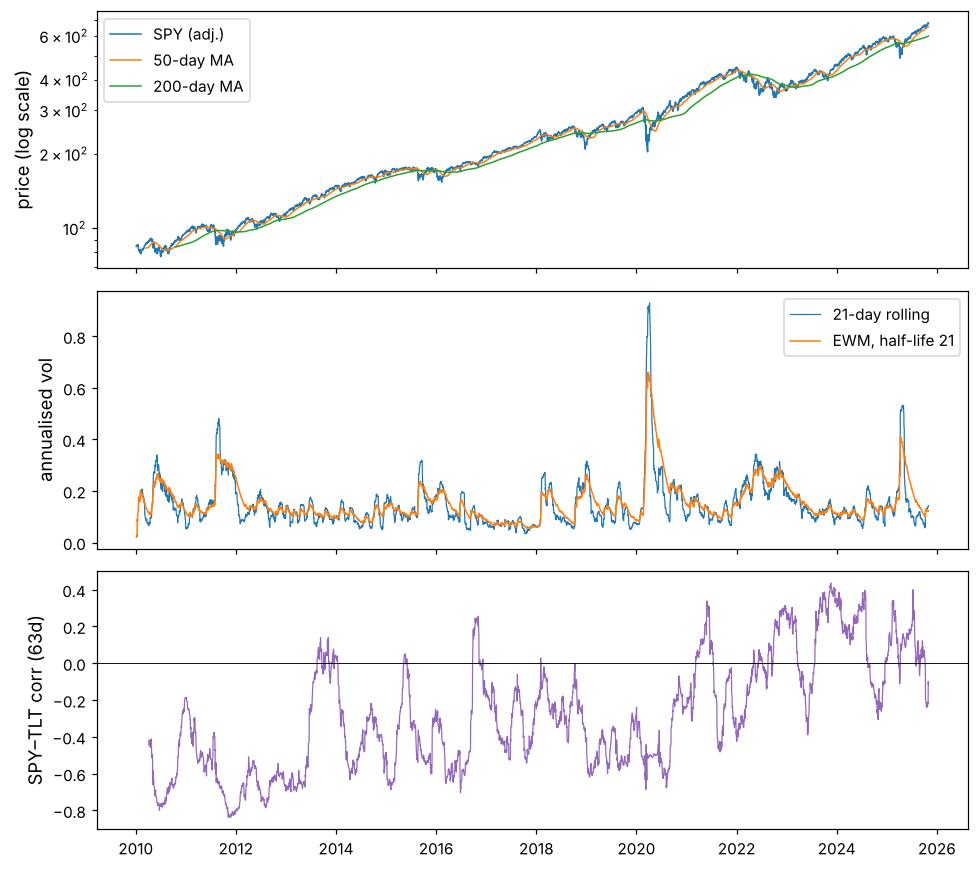

In [19]:
spy = close["SPY"]
ma50, ma200 = spy.rolling(50).mean(), spy.rolling(200).mean()
vol21 = rets["SPY"].rolling(21).std() * np.sqrt(252)            # 1-month realised vol, annualised
ewm_vol = rets["SPY"].ewm(halflife=21).std() * np.sqrt(252)
corr = rets["SPY"].rolling(63).corr(rets["TLT"])                  # 3-month stock-bond correlation
running_max = spy.expanding().max()
drawdown = spy / running_max - 1

fig, ax = plt.subplots(3, 1, figsize=(9, 8), sharex=True)
ax[0].plot(spy, lw=1, label="SPY (adj.)"); ax[0].plot(ma50, lw=1, label="50-day MA"); ax[0].plot(ma200, lw=1, label="200-day MA")
ax[0].set_yscale("log"); ax[0].legend(); ax[0].set_ylabel("price (log scale)")
ax[1].plot(vol21, lw=0.8, label="21-day rolling"); ax[1].plot(ewm_vol, lw=1, label="EWM, half-life 21")
ax[1].set_ylabel("annualised vol"); ax[1].legend()
ax[2].plot(corr, lw=0.8, color="tab:purple"); ax[2].axhline(0, color="k", lw=0.6)
ax[2].set_ylabel("SPY–TLT corr (63d)")
save_fig("rolling_windows")
plt.show()
R["vol_peak"] = f"{vol21.max():.0%}"
R["vol_peak_date"] = vol21.idxmax().strftime("%B %Y")
R["mdd"] = f"{drawdown.min():.0%}"
R["corr_2022"] = f"{corr.loc['2022'].mean():+.2f}"
R["corr_2010s"] = f"{corr.loc['2011':'2019'].mean():+.2f}"

![Figure 2-1. Rolling windows on real data: moving averages (top), realised volatility (middle) and the stock–bond correlation (bottom).](images/rolling_windows.png)

Three facts jump out, and each will come back in the Financial ML course:

- Volatility clusters: it peaked at 93% in April 2020 and stays high for weeks after a shock (Chapter 3 forecasts it).
- The worst SPY drawdown in the sample is -34%.
- The stock–bond correlation averaged -0.41 in 2011–2019 (bonds hedged stocks) but -0.02 in 2022, when stocks and bonds fell together. A portfolio built on the old correlation got hurt (Chapter 4).

:::quant
`rolling(21)` gives `NaN` for the first 20 rows: there is not a full window yet. `min_periods` lets you start earlier with fewer points. `ewm(halflife=h)` weights recent observations more, with weights halving every `h` days. It reacts faster to a new regime, which is why the RiskMetrics volatility model uses it. Both only use the past, so they are safe for signals.
:::

## groupby: split, apply, combine

`groupby` splits a table into groups, applies a function to each, and combines the results. The **Groupby** tab of the playground animates the three steps.

In [20]:
prices["ret"] = prices.groupby("ticker")["adj_close"].pct_change(fill_method=None)   # per ticker: never across tickers!
stats = prices.groupby("ticker")["ret"].agg(
    mean_daily="mean", vol_daily="std", best="max", worst="min", days="count")
stats["ann_return"] = (1 + stats["mean_daily"]) ** 252 - 1
stats["ann_vol"] = stats["vol_daily"] * np.sqrt(252)
stats["sharpe_0rf"] = stats["mean_daily"] / stats["vol_daily"] * np.sqrt(252)
print(stats.sort_values("sharpe_0rf", ascending=False).round(3))

        mean_daily  vol_daily   best  worst  days  ann_return  ann_vol  sharpe_0rf
ticker                                                                            
AAPL         0.001      0.018  0.153 -0.129  3982       0.319    0.283       0.978
QQQ          0.001      0.013  0.120 -0.120  3982       0.215    0.207       0.944
MSFT         0.001      0.016  0.142 -0.147  3982       0.258    0.255       0.897
SPY          0.001      0.011  0.105 -0.109  3982       0.158    0.173       0.849
JPM          0.001      0.017  0.180 -0.150  3982       0.208    0.276       0.685
KO           0.000      0.011  0.065 -0.097  3982       0.106    0.171       0.592
GLD          0.000      0.010  0.049 -0.088  3982       0.093    0.158       0.564
XOM          0.000      0.016  0.127 -0.122  3982       0.106    0.249       0.403
EEM          0.000      0.013  0.081 -0.125  3982       0.062    0.214       0.281
TLT          0.000      0.010  0.075 -0.067  3982       0.041    0.152       0.265


:::trap
`prices["adj_close"].pct_change()` on the long table would compute the “return” from the last AAPL price to the first EEM price where the tickers change. Group first. The same applies to `shift`, `rolling` and `diff` on long data.
:::

`transform` returns a result with the same shape as the input, aligned to the original rows. It is how you put a per-group statistic back into each row:

In [21]:
prices["ret_z"] = prices.groupby("ticker")["ret"].transform(lambda x: (x - x.mean()) / x.std())
prices["vol_63"] = prices.groupby("ticker")["ret"].transform(lambda x: x.rolling(63).std())
print(prices[["date", "ticker", "ret", "ret_z", "vol_63"]].dropna().tail(3))

            date ticker     ret   ret_z  vol_63
39827 2025-10-29    XOM  0.0123  0.7608  0.0114
39828 2025-10-30    XOM -0.0151 -0.9880  0.0113
39829 2025-10-31    XOM -0.0029 -0.2086  0.0110


### Cross-sectional ranks: comparing assets on each date

Grouping by **date** instead of ticker compares assets with each other on each day. This is the heart of cross-sectional strategies (Chapter 6): each month, rank assets on their past 12-month return and buy the leaders.

In [22]:
mom12 = monthly_px.pct_change(12, fill_method=None)            # 12-month return, per column
rank = mom12.rank(axis=1, ascending=False)        # 1 = strongest on that date
print(rank.tail(3))
top3_next_month = (rank.shift(1) <= 3)            # decided last month, held this month
strategy = (monthly_ret.where(top3_next_month)).mean(axis=1)
equal = monthly_ret.mean(axis=1)
both = pd.DataFrame({"top-3 momentum": strategy, "equal weight": equal}).dropna()
print(((1 + both).prod() ** (12 / len(both)) - 1).round(3).to_dict())

ticker      AAPL  EEM  GLD  JPM    KO  MSFT  QQQ  SPY   TLT   XOM
date                                                             
2025-08-31   7.0  5.0  1.0  2.0   9.0   3.0  4.0  6.0  10.0   8.0
2025-09-30   7.0  5.0  2.0  1.0  10.0   4.0  3.0  6.0   9.0   8.0
2025-10-31   7.0  5.0  1.0  2.0   8.0   4.0  3.0  6.0   9.0  10.0
{'top-3 momentum': 0.146, 'equal weight': 0.139}


The `shift(1)` makes sure we rank using information known at the end of the previous month. Whether the momentum version is really better, and whether the difference is luck, is exactly what the Financial ML course will teach you to test.

## Combining tables: `concat`, `merge`, `join`, `merge_asof`

In [23]:
fred = pd.read_csv(DATA / "fred_rates.csv", parse_dates=["date"])
spy_tbl = prices.loc[prices.ticker == "SPY", ["date", "adj_close"]]
m1 = spy_tbl.merge(fred, on="date", how="left")         # keep every SPY day
print(m1.tail(3))
print("how='left' keeps", len(m1), "rows; how='inner' keeps", len(spy_tbl.merge(fred, on="date")))

           date  adj_close  DGS3MO  DGS10  VIXCLS
3980 2025-10-29   680.0531    3.93   4.08   16.92
3981 2025-10-30   672.5738    3.92   4.11   16.91
3982 2025-10-31   674.7800    3.89   4.11   17.44
how='left' keeps 3983 rows; how='inner' keeps 3983


The **join type** decides what happens to rows without a partner: `inner` keeps only matches, `left` keeps all rows of the left table, `outer` keeps everything. Always check row counts after a merge; a key that is accidentally duplicated multiplies rows silently.

`pd.concat` stacks tables vertically (more rows) or side by side (`axis=1`), aligning on the index:

In [24]:
part1, part2 = close.loc["2024-12"], close.loc["2025-01"]
print(pd.concat([part1, part2]).shape, pd.concat([close["SPY"], close["TLT"]], axis=1).shape)

(41, 10) (3983, 2)


### `merge_asof`: the point-in-time join

Economic data is released with a delay. If inflation for March is published on 10 April, a backtest may use it only from 10 April. `merge_asof` joins each row to the **most recent** row of the other table at or before its date, which is exactly “what was known at the time”.

In [25]:
releases = pd.DataFrame({
    "date": pd.to_datetime(["2025-03-12", "2025-04-10", "2025-05-13"]),
    "cpi_yoy": [2.8, 2.4, 2.3],                     # announced on these dates
})
days = pd.DataFrame({"date": pd.bdate_range("2025-04-08", "2025-04-14")})
print(pd.merge_asof(days, releases, on="date", direction="backward"))

        date  cpi_yoy
0 2025-04-08      2.8
1 2025-04-09      2.8
2 2025-04-10      2.4
3 2025-04-11      2.4
4 2025-04-14      2.4


## Performance and good style

### Vectorise instead of `apply` and loops

In [26]:
import time
x = prices["ret"].fillna(0)
t0 = time.perf_counter(); slow = x.apply(lambda v: max(v, 0)); t1 = time.perf_counter()
fast = x.clip(lower=0); t2 = time.perf_counter()
print(f"apply {1000*(t1-t0):.1f} ms vs clip {1000*(t2-t1):.2f} ms, equal: {slow.equals(fast)}")
R["apply_ratio"] = f"{(t1 - t0) / (t2 - t1):.0f}"

apply 9.4 ms vs clip 0.88 ms, equal: True


The vectorised method was about 11 times faster. `apply` with a Python function runs a Python call per row; methods such as `clip`, `where`, `rolling`, `rank` and arithmetic run in compiled code.

### Method chaining

Building a result as a chain of small steps, each returning a new DataFrame, reads top to bottom like a recipe and avoids half-modified intermediate variables. `assign` adds columns, `pipe` applies your own function.

In [27]:
def annualise(df, periods=252):
    return df.assign(ann_vol=df["vol"] * np.sqrt(periods))

summary = (
    prices
    .loc[lambda d: d["date"] >= "2020-01-01"]
    .groupby("ticker", as_index=False)
    .agg(vol=("ret", "std"), last_price=("close", "last"))
    .pipe(annualise)
    .sort_values("ann_vol")
)
summary

,ticker,vol,last_price,ann_vol
2,GLD,0.0103,368.12,0.1627
8,TLT,0.0109,90.29,0.1730
4,KO,0.0129,68.90,0.2043
7,SPY,0.0132,682.06,0.2094
1,EEM,0.0138,55.30,0.2191
6,QQQ,0.0161,629.07,0.2550
5,MSFT,0.0188,517.81,0.2978
3,JPM,0.0199,311.12,0.3157
0,AAPL,0.0203,270.37,0.3217
9,XOM,0.0209,114.36,0.3312


### Memory: categories and file formats

In [28]:
mem_obj = prices["ticker"].astype(object).memory_usage(deep=True)
mem_cat = prices["ticker"].astype("category").memory_usage(deep=True)
print(f"ticker column: {mem_obj/1e6:.2f} MB as Python strings, {mem_cat/1e6:.3f} MB as category")
prices.to_parquet("prices.parquet")            # columnar, typed, compressed
import os
print(f"CSV {os.path.getsize(DATA / 'prices_long.csv')/1e6:.1f} MB vs Parquet {os.path.getsize('prices.parquet')/1e6:.1f} MB")
print(pd.read_parquet("prices.parquet").dtypes.head(3))
os.remove("prices.parquet")

ticker column: 2.08 MB as Python strings, 0.040 MB as category


CSV 2.3 MB vs Parquet 2.5 MB


date      datetime64[us]
ticker               str
open             float64
dtype: object


Parquet keeps the dtypes (dates stay dates), loads many times faster than CSV and is the standard format for research data. CSV is fine for sharing small files.

## A small case study: the crash of March 2020

Everything together: select a window, compute drawdowns per asset, and see which assets protected a portfolio.

In [29]:
window = close.loc["2020-02-19":"2020-03-23"]
crash = (window.iloc[-1] / window.iloc[0] - 1).sort_values()
worst_dd = (window / window.cummax() - 1).min()
corr_before = rets.loc["2019"].corr()["SPY"]
corr_during = rets.loc["2020-02-19":"2020-03-23"].corr()["SPY"]
table = pd.DataFrame({"return": crash, "max drawdown": worst_dd,
                      "corr with SPY 2019": corr_before, "corr during crash": corr_during}).sort_values("return")
print(table.round(2))
R["tlt_crash"] = f"{crash['TLT']:+.0%}"
R["spy_crash"] = f"{crash['SPY']:+.0%}"

        return  max drawdown  corr with SPY 2019  corr during crash
ticker                                                             
XOM      -0.48         -0.48                0.64               0.89
JPM      -0.43         -0.43                0.70               0.93
KO       -0.37         -0.37                0.33               0.85
SPY      -0.34         -0.34                1.00               1.00
EEM      -0.31         -0.31                0.76               0.93
AAPL     -0.31         -0.31                0.74               0.97
QQQ      -0.28         -0.29                0.95               0.98
MSFT     -0.27         -0.28                0.81               0.96
GLD      -0.04         -0.13               -0.27              -0.01
TLT       0.14         -0.16               -0.46              -0.50


From 19 February to 23 March 2020 SPY moved -34% while long Treasuries moved +14%. Notice how the correlations of the stocks with SPY rose during the crash: diversification across stocks weakens exactly when you need it.

## The mistakes that cost quants money

| Mistake | What happens | Fix |
|---|---|---|
| Using `close` instead of `adj_close` | Dividends and splits distort returns | Use adjusted prices for returns |
| `pct_change`/`shift` on long data without `groupby` | Returns across different tickers | `groupby("ticker")` first |
| `shift(-1)` or `bfill` in features | Look-ahead bias, fake profits | Features use only `shift(k ≥ 0)`, `ffill` |
| Chained assignment `df[m]["c"] = v` | Nothing changes | `df.loc[m, "c"] = v` |
| Merge with duplicated keys | Rows multiply silently | Check `len` before and after; `validate="one_to_one"` |
| Forgetting `NaN` alignment | Statistics on fewer days than you think | Check `.count()`, decide `dropna`/`ffill` |
| Dates as strings | No resampling, wrong sorting | `parse_dates`, `pd.to_datetime` |
| `apply` with a lambda on big data | 10–100× slower | Vectorised methods |

## Exercises

:::exercise
1. From `prices`, build a wide table of daily **volumes** and find, for each ticker, the date of its highest volume.
2. Compute each asset's annual returns for 2015–2024 from `close` with `resample`, and the number of years each asset beat SPY.
3. Compute the rolling 1-year beta of AAPL to SPY: $\beta = \text{Cov}(r_A, r_M) / \text{Var}(r_M)$ with `rolling(252)`. When was it highest?
4. Create a column `next_ret` with each ticker's *next-day* return (the target), and check, using `corr`, whether today's return predicts tomorrow's for SPY. Be careful about which shift goes where.
5. For each calendar month name (January, February, …), compute the average SPY monthly return across years. Is there a “best month”? How many years back each average?
6. Use `merge_asof` to attach to every SPY trading day the latest **weekly** close of GLD known at that date.
:::

<details><summary>Solutions</summary>

In [30]:
# 1
vol_wide = prices.pivot(index="date", columns="ticker", values="volume")
print(vol_wide.idxmax().dt.date)

# 2
ann = close.resample("YE").last().pct_change(fill_method=None).loc["2015":"2024"]
print(ann.gt(ann["SPY"], axis=0).sum().drop("SPY"))

# 3
cov = rets["AAPL"].rolling(252).cov(rets["SPY"])
beta = cov / rets["SPY"].rolling(252).var()
print(f"highest beta {beta.max():.2f} on {beta.idxmax().date()}")

# 4
prices["next_ret"] = prices.groupby("ticker")["ret"].shift(-1)     # target only!
spy_rows = prices[prices.ticker == "SPY"]
print("corr(today, tomorrow) for SPY:", round(spy_rows["ret"].corr(spy_rows["next_ret"]), 3))

# 5
sm = monthly_ret["SPY"].dropna()
by_month = sm.groupby(sm.index.month_name()).agg(["mean", "count"])
print(by_month.sort_values("mean", ascending=False).round(4).head(4))

# 6
gld_w = close["GLD"].resample("W-FRI").last().rename("gld_weekly").reset_index()
spy_days = close["SPY"].reset_index()
print(pd.merge_asof(spy_days, gld_w, on="date").tail(3))

ticker
AAPL    2011-01-18
EEM     2010-05-06
GLD     2013-04-15
JPM     2012-05-11
KO      2012-09-21
MSFT    2011-04-29
QQQ     2010-05-07
SPY     2011-08-09
TLT     2025-04-09
XOM     2010-06-25
dtype: object
ticker
AAPL    7
EEM     1
GLD     4
JPM     7
KO      3
MSFT    8
QQQ     7
TLT     1
XOM     3
dtype: int64
highest beta 1.59 on 2021-07-19
corr(today, tomorrow) for SPY: -0.105
            mean  count
date                   
November  0.0328     15
July      0.0296     16
October   0.0227     16
January   0.0135     15
           date       SPY  gld_weekly
3980 2025-10-29  680.0531      377.52
3981 2025-10-30  672.5738      377.52
3982 2025-10-31  674.7800      368.12


</details>

## What's next

You can now load, clean, reshape and analyse a market dataset. Toolkit Chapter 3 turns those tables into clear charts, from a single line plot to a full market report, and finishes the toolkit.